In [160]:
import matplotlib.pyplot as plt
import os
import numpy as np
import json

In [161]:
fontsize_legend = 16
fontsize_label = 22
fontsize_ticks = 18

In [181]:
seeds = [0, 1, 5, 6, 7, 9, 11, 13, 15, 16, 17, 18, 19, 20, 21]
machines = range(3, 8)
methods = [
    'Random', 'RoundRobin',
    # 'STOP-V=250', 
    'STOP-V=500',
    'Li2024-WithoutCapacityConstraints-V=0.01',
    # 'Li2024-WithoutCapacityConstraints-V=0.1',
    # 'Li2024-WithoutCapacityConstraints-V=1',
]
max_d = 3000
C_avg = .005
R_avg = 8

In [189]:
method2name = {
    'Random': 'Random',
    'RoundRobin': 'RoundRobin',
    'Li2024-WithoutCapacityConstraints-V=0.01': r'eGLB_U ($V=0.01$)',
    'Li2024-WithoutCapacityConstraints-V=0.1': r'eGLB_U ($V=0.1$)',
    'Li2024-WithoutCapacityConstraints-V=1': r'eGLB_U ($V=1$)',
    # 'Li2024-AllDemandsExecuted-V=0.0': 'eGLB'
}
method2color = {
    'Random': [.8, .8, 0],
    'RoundRobin': [1, .6, 0],
    'STOP-V=250': [1, 0, .3, .5], 
    'STOP-V=500': [1, 0, .3], 
    'Li2024-WithoutCapacityConstraints-V=0.01': [0, .5, 1],
    'Li2024-WithoutCapacityConstraints-V=0.1': [0, .5, 1, .75],
    'Li2024-WithoutCapacityConstraints-V=1': [0, .5, 1, .5],
    # 'Li2024-AllDemandsExecuted-V=0.0': [0, .6, .6]
}

In [190]:
def get_path(model, method, n_m, max_d, id, C_avg=None, R_avg=None):
    path = f'results/{model}/{method}/n_m={n_m}-max_d={max_d}'
    if 'STOP' in method or 'Li' in method:
        path += f'/C_avg={C_avg}-R_avg={R_avg}'
    path += f'/id={id}'
    return path

In [191]:
def get_data(path):
    data = dict()
    for t in range(300):
        if os.path.isfile(f'{path}/t={t}.json'):
            with open(f'{path}/t={t}.json', 'r') as f:
                d = json.load(f)
            keys = list(d.keys())
            for key in keys:
                if key not in data:
                    data[key] = list()
                data[key].append(d[key])
        else:
            print(f'File {path}/t={t}.json does not exist.')
            break
    for key in keys:
        try:
            data[key] = np.asarray(data[key]).astype('float32')
        except:
            pass
    Q_k = np.mean(data['Q_k'])
    throughput = np.sum(data['throughput']) / np.sum(data['arrivals']) * 100
    performance = np.mean(data['performance'])
    elapsed_time = np.mean(data['elapsed_time'])
    emission_k = np.mean(data['emission_k'])
    response_time_k = np.mean(data['response_time_k'])
    return {
        'Q_k': Q_k.item(),
        'throughput': throughput.item(),
        'performance': performance.item(),
        'elapsed_time': elapsed_time.item(),
        'emission_k': emission_k.item(),
        'response_time_k': response_time_k.item()
    }

def open_data():
    method2n_m2data = dict()
    for method in methods:
        method2n_m2data[method] = dict()
        for n_m in machines:
            method2n_m2data[method][n_m] = dict()
            for s in seeds:
                d = get_data(get_path('Yolo', method, n_m, max_d, s, C_avg, R_avg))
                for k in d:
                    if k not in method2n_m2data[method][n_m]:
                        method2n_m2data[method][n_m][k] = list()
                    method2n_m2data[method][n_m][k].append(d[k])
    return method2n_m2data
method2n_m2data = open_data()

In [192]:
metrics = ['throughput', 'performance', 'elapsed_time', 'Q_k', 'emission_k', 'response_time_k']

In [193]:
def get_positions(machines, methods, gap=.1):
    positions = {}
    for i, n_m in enumerate(machines):
        positions[n_m] = {}
        base = i * (len(methods) + gap)
        for j, method in enumerate(methods):
            positions[n_m][method] = base + j
    return positions
positions = get_positions(machines, methods)

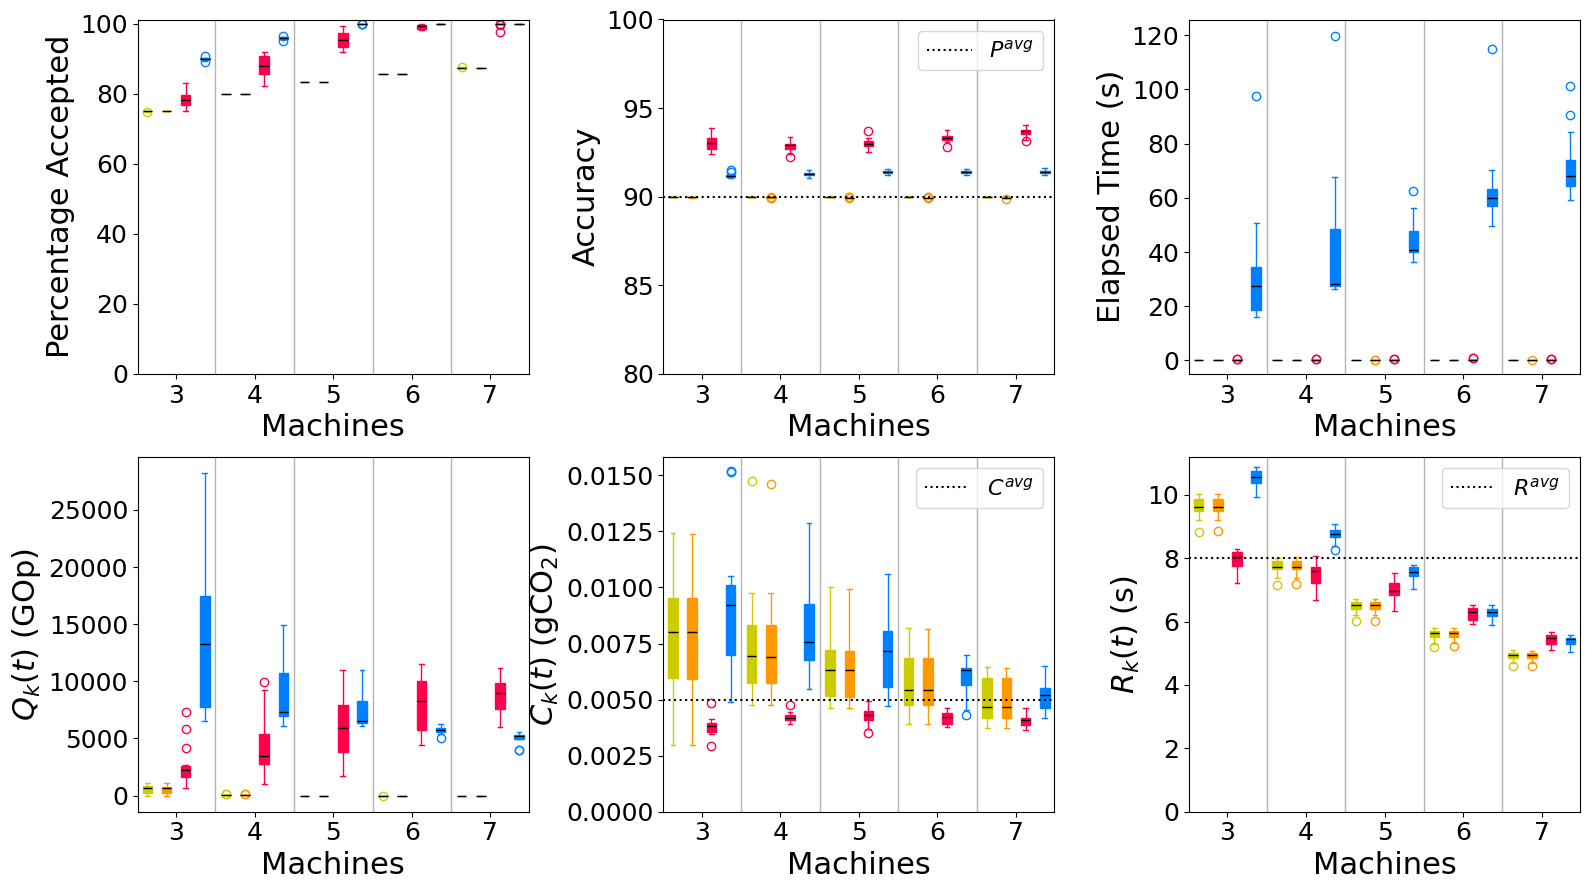

In [196]:
def plot():
    width = .5
    fig, axs = plt.subplots(2, 3, figsize=(16, 9))
    axs = axs.ravel()
    for metric, ax in zip(metrics, axs):
        for method in methods:
            data = [method2n_m2data[method][n_m][metric] for n_m in machines]
            pos = [positions[n_m][method] for n_m in machines]
            ax.boxplot(data, positions=pos, 
                medianprops=dict(color='black'), 
                boxprops=dict(facecolor=method2color[method], color=method2color[method]),
                capprops=dict(color=method2color[method]),
                whiskerprops=dict(color=method2color[method]),
                flierprops=dict(color=method2color[method], markeredgecolor=method2color[method]),
                widths=width, patch_artist=True)
        for i in range(len(machines) - 1):
            rightmost = max(positions[machines[i]].values())
            leftmost = min(positions[machines[i+1]].values())
            sep = (rightmost + leftmost) / 2
            ax.axvline(sep, color='black', linestyle='-', linewidth=1, alpha=.3)
        ax.tick_params(axis='y', labelsize=fontsize_ticks)
        ax.set_xticks([np.mean([positions[n_m][m] for m in methods]) for n_m in machines], labels=machines, fontsize=fontsize_ticks)
        ax.set_xlabel("Machines", fontsize=fontsize_label)
        if metric == 'throughput':
            ax.set_yticks(ticks=np.arange(0, 101, 20), labels=range(0, 101, 20))
            ax.set_ylabel("Percentage Accepted", fontsize=fontsize_label)
        if metric == 'performance':
            ax.set_ylim((80, 100))
            ax.axhline(90, c='black', linestyle='dotted', label=r'$P^{avg}$')
            ax.set_ylabel("Accuracy", fontsize=fontsize_label)
            ax.legend(fontsize=fontsize_legend)
        if metric == 'elapsed_time':
            ax.set_ylim((-5, None))
            ax.set_ylabel("Elapsed Time (s)", fontsize=fontsize_label)
        if metric == 'Q_k':
            ax.set_ylabel(r"$Q_k(t)$ (GOp)", fontsize=fontsize_label)
            # ax.set_yscale('log')
        if metric == 'emission_k':
            ax.axhline(C_avg, c='black', linestyle='dotted', label=r'$C^{avg}$')
            ax.legend(fontsize=fontsize_legend)
            ax.set_ylim((0, None))
            ax.set_ylabel(r"$C_k(t)$ (gCO$_2$)", fontsize=fontsize_label)
        if metric == 'response_time_k':
            ax.axhline(R_avg, c='black', linestyle='dotted', label=r'$R^{avg}$')
            ax.legend(fontsize=fontsize_legend)
            ax.set_ylim((0, None))
            ax.set_ylabel(r"$R_k(t)$ (s)", fontsize=fontsize_label)


    fig.tight_layout()
    plt.show()
    plt.close(fig)
plot()